# Pre Processing

- Read the data
- Descriptive Statistics
- Drop unnecessary columns
- Check missing values
- Check outliers, if there any cap them with IQR method. Note that you need only do capping for columns which has unique values more than 2.
- Use standartization for data 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from kneed import KneeLocator
import scipy.cluster.hierarchy as shc

### Read the data

In [2]:
data = pd.read_csv(r"C:/Users/aksta/Desktop/python lessons/Bank_Personal_Loan.csv")

# CCAvg is text with '/' as the decimal point ('1/60' = 1.6)
data['CCAvg'] = data['CCAvg'].astype(str).str.replace('/', '.', regex=False).astype(float)

data.head()

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


### Descriptive Statistics

In [3]:
data.describe(include='all')

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


### Drop unnecessary columns

- `ID` = row number, `ZIP Code` = location code (not a measurement) -> dropped.
- `Personal Loan` is a result column, clustering has no target -> it is **not** used for clustering. It is kept aside (`loan_flag`) only to describe the segments at the end.

In [4]:
loan_flag = data['Personal Loan'].copy()

data.drop(['ID', 'ZIP Code', 'Personal Loan'], axis=1, inplace=True)
data.head()

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard
0,25,1,49,4,1.6,1,0,1,0,0,0
1,45,19,34,3,1.5,1,0,1,0,0,0
2,39,15,11,1,1.0,1,0,0,0,0,0
3,35,9,100,1,2.7,2,0,0,0,0,0
4,35,8,45,4,1.0,2,0,0,0,0,1


### Check missing values

In [5]:
data.isnull().sum()

Age                   0
Experience            0
Income                0
Family                0
CCAvg                 0
Education             0
Mortgage              0
Securities Account    0
CD Account            0
Online                0
CreditCard            0
dtype: int64

### Check outliers (columns with more than 2 unique values)

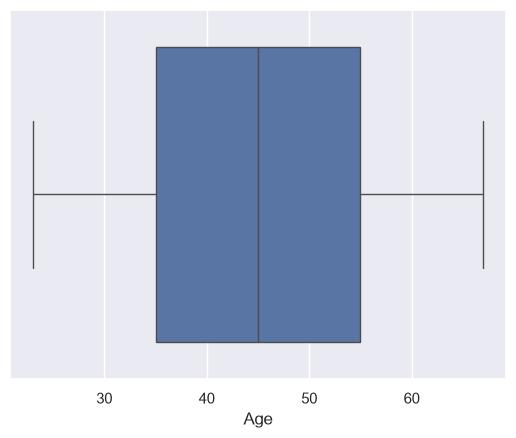

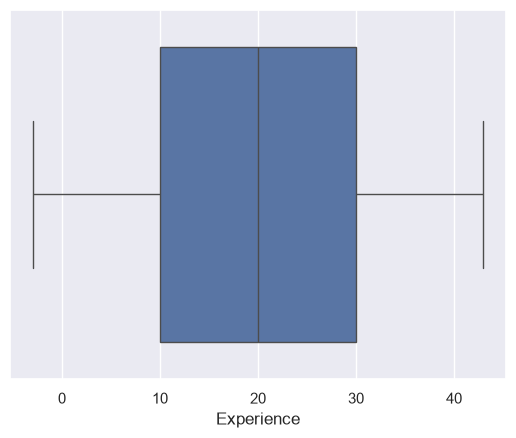

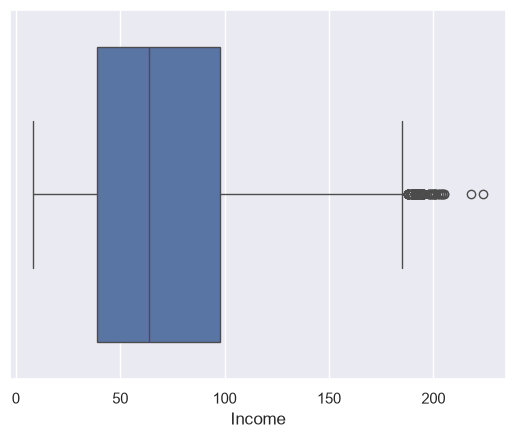

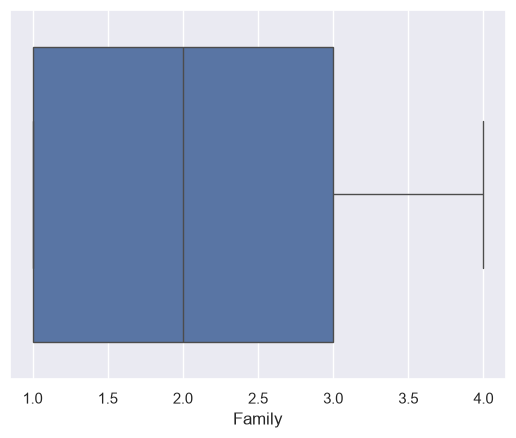

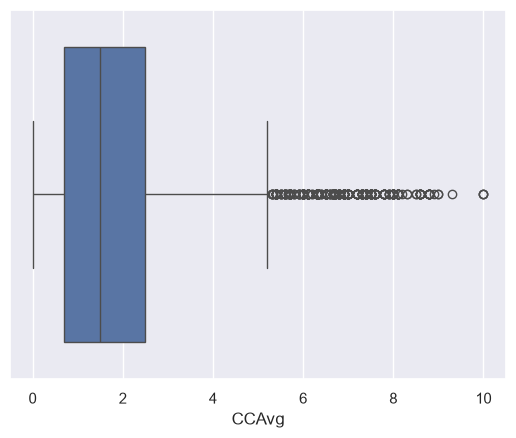

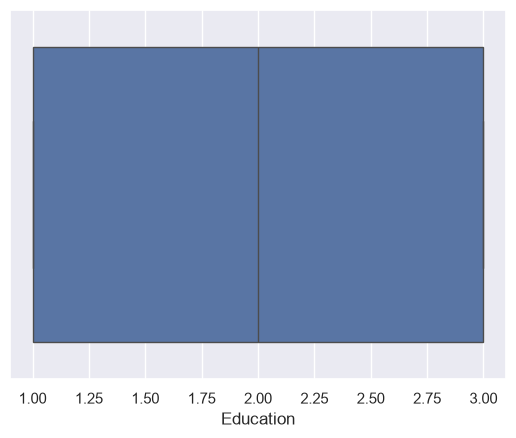

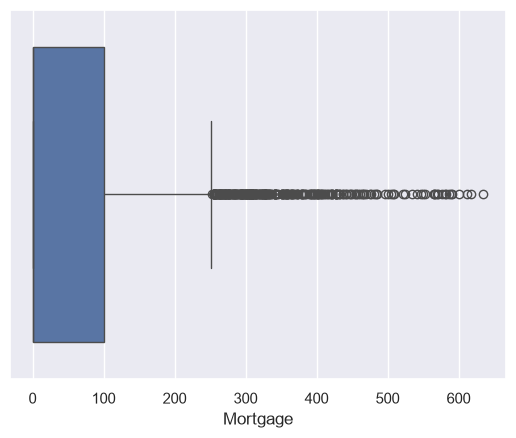

In [6]:
for i in data.columns:
    if data[i].nunique()>2:
        sns.boxplot(x=i, data=data)
        plt.show()

`Experience` has impossible negative values (-1, -2, -3), they are set to 0 first. Then the IQR capping is done only for columns with more than 2 unique values (0/1 columns are untouched).

negative Experience rows: 52
capped columns: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Education', 'Mortgage']
Age: 0 outliers capped to [5.00, 85.00]
Experience: 0 outliers capped to [-20.00, 60.00]
Income: 96 outliers capped to [-49.50, 186.50]
Family: 0 outliers capped to [-2.00, 6.00]
CCAvg: 324 outliers capped to [-2.00, 5.20]
Education: 0 outliers capped to [-2.00, 6.00]
Mortgage: 291 outliers capped to [-151.50, 252.50]


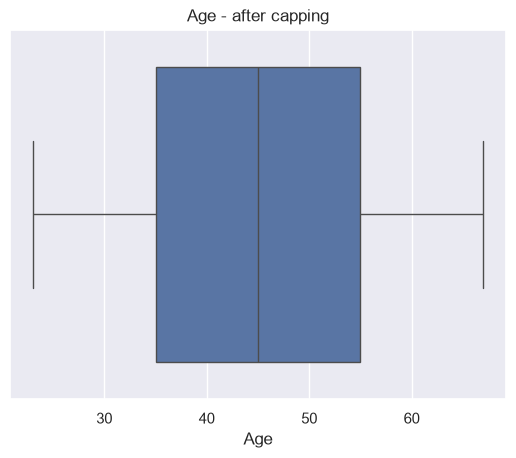

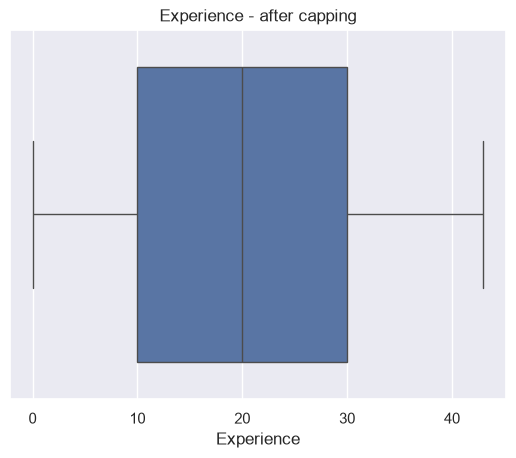

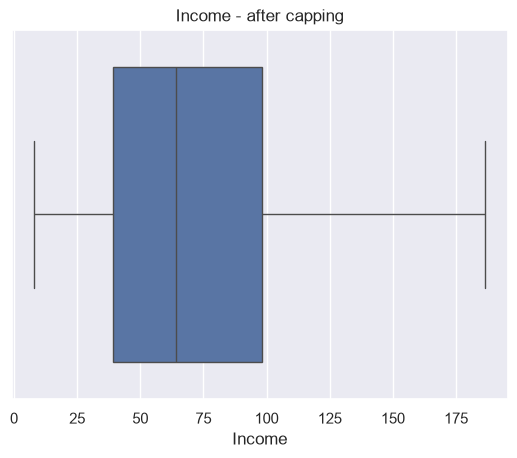

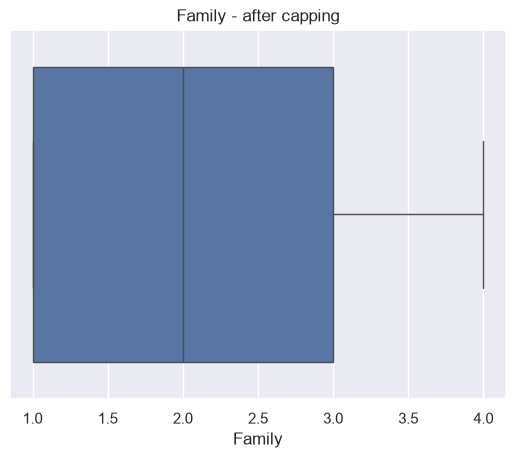

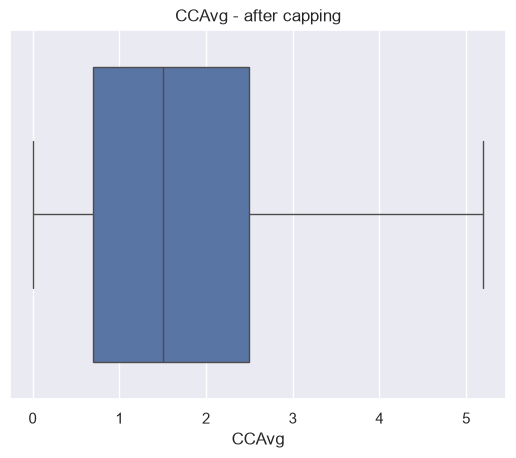

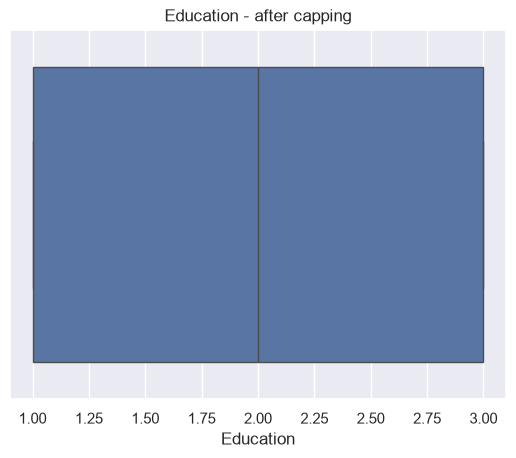

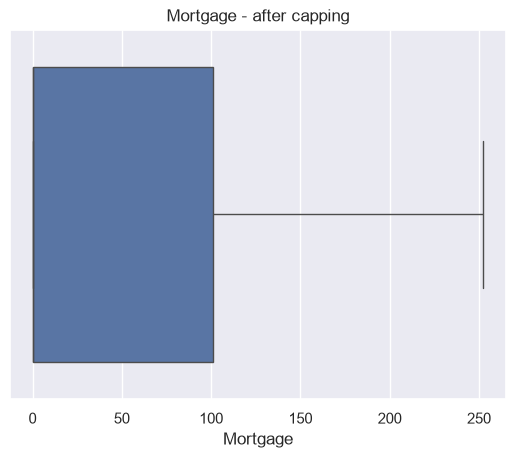

In [7]:
print('negative Experience rows:', (data['Experience'] < 0).sum())
data['Experience'] = data['Experience'].clip(lower=0)

cap_cols = [c for c in data.columns if data[c].nunique() > 2]
print('capped columns:', cap_cols)

q1 = data[cap_cols].quantile(0.25)
q3 = data[cap_cols].quantile(0.75)
IQR = q3 - q1

Lower = q1 - 1.5 * IQR
Upper = q3 + 1.5 * IQR

for i in cap_cols:
    n_out = ((data[i] < Lower[i]) | (data[i] > Upper[i])).sum()
    data[i] = data[i].clip(lower=Lower[i], upper=Upper[i])
    print(f'{i}: {n_out} outliers capped to [{Lower[i]:.2f}, {Upper[i]:.2f}]')

for i in cap_cols:
    sns.boxplot(x=i, data=data)
    plt.title(f'{i} - after capping')
    plt.show()

### Standardization

In [8]:
scaler = StandardScaler()
data_std = scaler.fit_transform(data)

data_scaled = pd.DataFrame(data_std, columns=data.columns)
data_scaled.head()

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard
0,-1.774417,-1.671390,-0.539600,1.397414,-0.159316,-1.049078,-0.608391,2.928915,-0.25354,-1.216618,-0.645314
1,-0.029524,-0.097873,-0.868392,0.525991,-0.228183,-1.049078,-0.608391,2.928915,-0.25354,-1.216618,-0.645314
2,-0.552992,-0.447543,-1.372540,-1.216855,-0.572519,-1.049078,-0.608391,-0.341423,-0.25354,-1.216618,-0.645314
3,-0.901970,-0.972049,0.578292,-1.216855,0.598223,0.141703,-0.608391,-0.341423,-0.25354,-1.216618,-0.645314
4,-0.901970,-1.059467,-0.627278,1.397414,-0.572519,0.141703,-0.608391,-0.341423,-0.25354,-1.216618,1.549632


# Modeling

## 1. K Means model by default

- Calculate wcss and silhuette score for 7 centroids - range(1, 8)
- Use KneeLocator to detect elbow ( centroids )
- Build Kmeans model by preferred centroid
- Create target cluster predicting on data and name column as Segment_KM
- Analyse each cluster by groupby method ( Which one is your target group )
- Plot scatter between choosen columns by given Segment_KM

In [9]:
wcss = []
silhouette_scores = []

for i in range(1, 8):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(data_scaled)

    wcss.append(kmeans.inertia_)
    print(f"Cluster {i}: WCSS = {kmeans.inertia_:.4f}")

    if i > 1:
        sil = silhouette_score(data_scaled, kmeans.predict(data_scaled))
        silhouette_scores.append(sil)
        print(f"Silhouette Score = {sil:.4f}")
    else:
        print(" (Silhouette Score not applicable for k=1)")

Cluster 1: WCSS = 55000.0000
 (Silhouette Score not applicable for k=1)
Cluster 2: WCSS = 47470.8846
Silhouette Score = 0.1392
Cluster 3: WCSS = 41590.5676
Silhouette Score = 0.1573
Cluster 4: WCSS = 37319.8039
Silhouette Score = 0.1609
Cluster 5: WCSS = 35075.5073
Silhouette Score = 0.1487
Cluster 6: WCSS = 33253.7294
Silhouette Score = 0.1427
Cluster 7: WCSS = 30662.8835
Silhouette Score = 0.1600


The optimal number of clusters (elbow point) is: 4


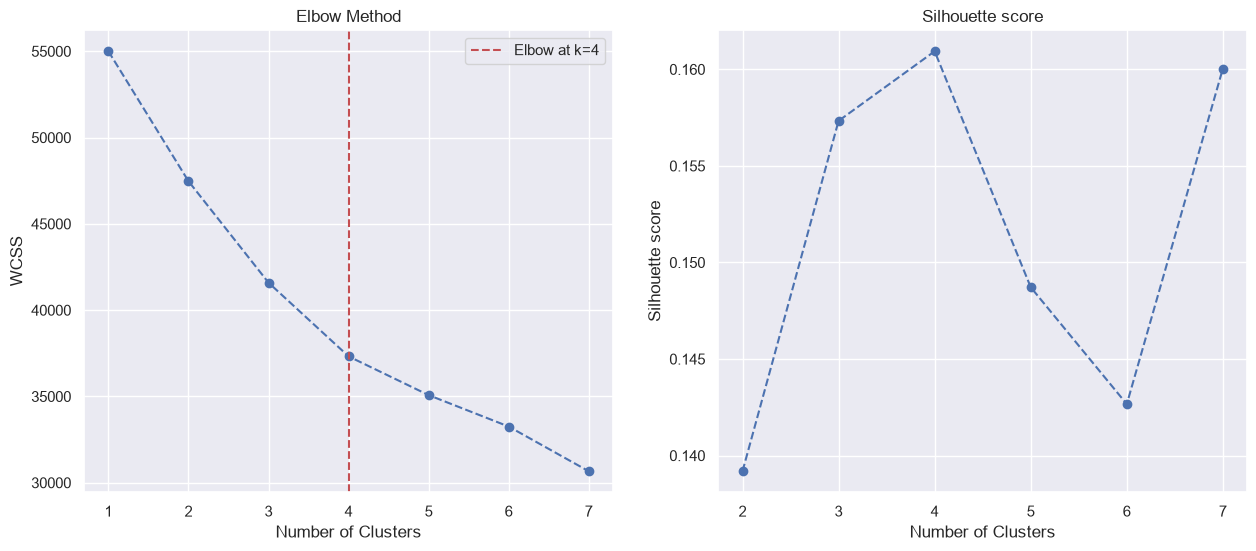

In [10]:
knee_locator = KneeLocator(range(1, 8), wcss, curve="convex", direction="decreasing")
optimal_k = knee_locator.elbow
print(f"The optimal number of clusters (elbow point) is: {optimal_k}")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].plot(range(1, 8), wcss, marker="o", linestyle="--")
ax[0].axvline(optimal_k, linestyle="--", color="r", label=f"Elbow at k={optimal_k}")
ax[0].set_xlabel("Number of Clusters"); ax[0].set_ylabel("WCSS"); ax[0].set_title("Elbow Method"); ax[0].legend()

ax[1].plot(range(2, 8), silhouette_scores, marker="o", linestyle="--")
ax[1].set_xlabel("Number of Clusters"); ax[1].set_ylabel("Silhouette score"); ax[1].set_title("Silhouette score")
plt.show()

In [11]:
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
kmeans.fit(data_scaled)

data['Segment_KM'] = kmeans.predict(data_scaled)
data['Segment_KM'].value_counts().sort_index()

Segment_KM
0     863
1    1871
2    1964
3     302
Name: count, dtype: int64

In [12]:
orig_cols = list(data_scaled.columns)

def segment_table(seg_col):
    t = data.groupby(seg_col)[orig_cols].mean()
    t['customer count'] = data.groupby(seg_col)['Age'].count()
    t['share of customers'] = t['customer count'] / t['customer count'].sum()
    # extra column, NOT used for clustering: real loan acceptance rate of the segment
    t['loan acceptance rate'] = loan_flag.groupby(data[seg_col]).mean()
    return t.round(3)

segment_table('Segment_KM')

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard,customer count,share of customers,loan acceptance rate
Segment_KM,,,,,,,,,,,,,,
0,44.525,19.516,137.753,1.788,3.917,1.432,72.202,0.065,0.0,0.550,0.221,863,0.173,0.267
1,35.012,9.784,59.064,2.639,1.333,1.951,45.380,0.088,0.0,0.561,0.262,1871,0.374,0.031
2,55.477,30.161,54.591,2.423,1.264,2.005,42.339,0.078,0.0,0.599,0.279,1964,0.393,0.026
3,45.702,20.573,104.242,2.460,2.652,1.927,73.190,0.487,1.0,0.937,0.795,302,0.060,0.464


**Target group (K-Means, k = 4): Segment_KM = 0** - 863 customers (17.3%), highest income (about 138), highest card spending (CCAvg about 3.9), small families, mostly graduate-level education. 27% of them really took a personal loan, about 9 times more than the two big low-income segments (3% and 2.6%).
Segment 3 (302 customers, 6%, all have a CD account) has the highest rate (46%) but is a small niche - second choice.

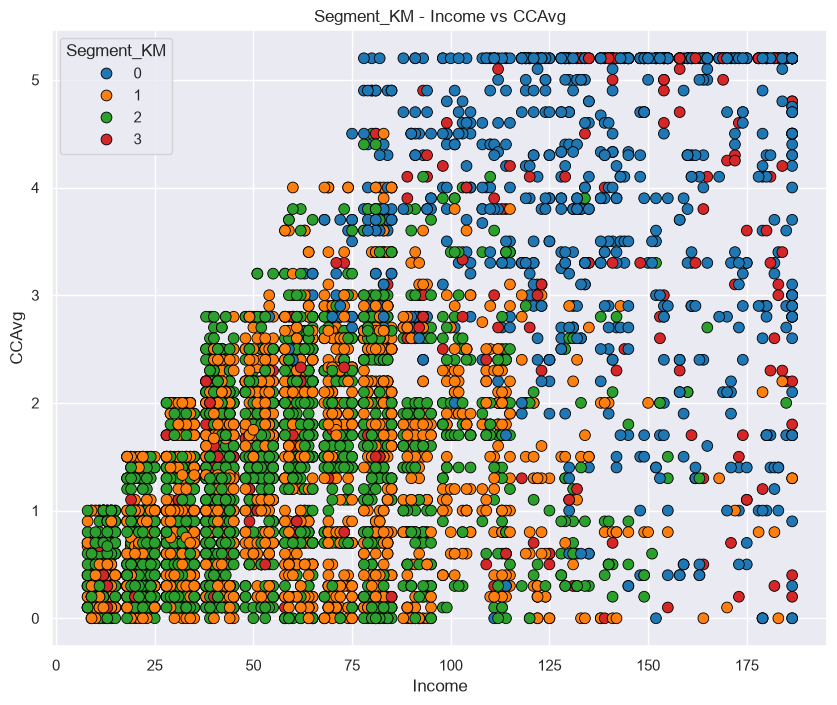

In [13]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x=data['Income'], y=data['CCAvg'], hue=data['Segment_KM'], palette='tab10', s=60, edgecolor="black")
plt.title('Segment_KM - Income vs CCAvg')
plt.show()

## 2. K Means model by PCA

- Build PCA() model for whole scaled data and show explained variance ratio for each variable
- By plotting Cumulative Explained Variance choose how many component will be used in order to complete PCA(). Best practise is above 80%.
- By chosen components build PCA() on scaled data
- Create dataframe where rows are new components and columns are previous variables, and analyse which component describes previous variables. 
- Calculate scores_pca from new components
- Create a dataframe called pca_df where newly created components will be named as variables 
- Calculate wcss and silhuette score for 7 centroids - range(1, 8)
- Use KneeLocator to detect elbow ( centroids )
- Build Kmeans model by preferred centroid
- Create target cluster predicting on data and name column as Segment_KM_PCA
- concat data and pca_df
- Analyse each cluster by groupby method ( Which one is your target group )
- Plot scatter between data['Variable_2'] and data['Variable_1'] columns by given Segment_KM_PCA

In [14]:
pca = PCA()
pca.fit(data_scaled)

pd.Series(pca.explained_variance_ratio_, index=[f'Component {i+1}' for i in range(len(pca.explained_variance_ratio_))]).round(4)

Component 1     0.1855
Component 2     0.1658
Component 3     0.1281
Component 4     0.0924
Component 5     0.0911
Component 6     0.0896
Component 7     0.0845
Component 8     0.0841
Component 9     0.0466
Component 10    0.0319
Component 11    0.0005
dtype: float64

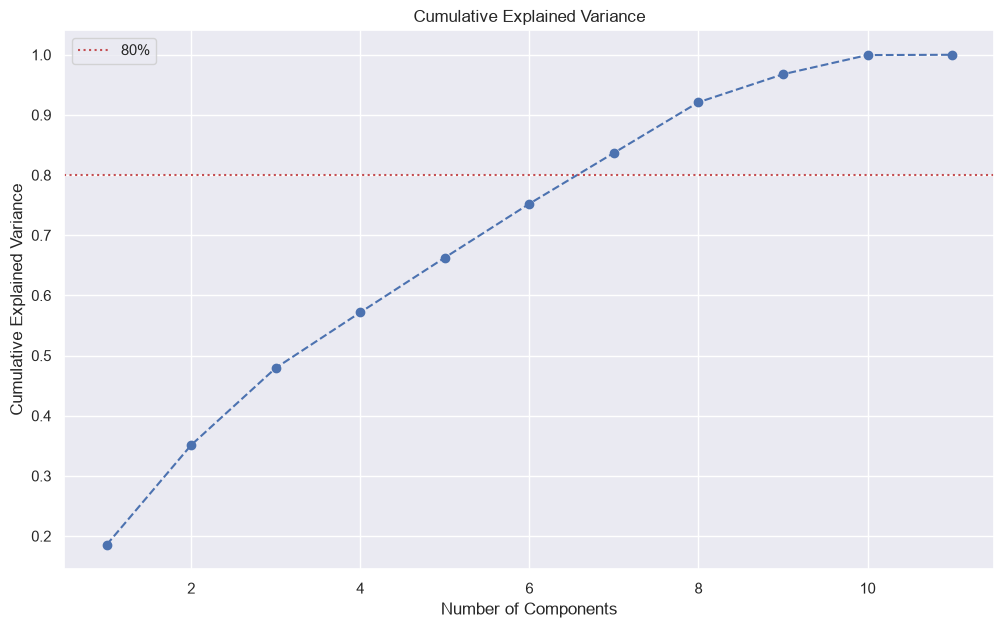

Components needed for >= 80% variance: 7 | explained: 0.8369


In [15]:
cum_var = pca.explained_variance_ratio_.cumsum()

plt.figure(figsize=(12, 7))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', linestyle='--')
plt.axhline(0.8, color='r', linestyle=':', label='80%')
plt.title('Cumulative Explained Variance')
plt.xlabel('Number of Components'); plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.show()

n_comp = int(np.argmax(cum_var >= 0.80) + 1)
print('Components needed for >= 80% variance:', n_comp, '| explained:', round(cum_var[n_comp - 1], 4))

In [16]:
pca = PCA(n_components=n_comp)
pca.fit(data_scaled)

df_pca_comp = pd.DataFrame(data=pca.components_,
                           columns=data_scaled.columns.values,
                           index=[f'Component {i+1}' for i in range(n_comp)])
df_pca_comp.round(2)

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard
Component 1,0.65,0.64,-0.27,0.01,-0.26,0.12,-0.07,-0.03,-0.08,-0.00,-0.01
Component 2,0.27,0.28,0.56,-0.21,0.53,-0.21,0.16,0.13,0.32,0.09,0.11
Component 3,-0.04,-0.05,-0.20,0.23,-0.19,0.17,-0.02,0.47,0.61,0.27,0.41
Component 4,-0.01,-0.01,-0.00,-0.06,-0.04,-0.03,0.07,-0.60,0.02,-0.13,0.78
Component 5,0.03,0.02,0.04,0.29,0.04,0.36,0.69,0.11,0.02,-0.54,-0.03
Component 6,0.01,0.00,0.03,0.24,-0.03,0.09,0.48,-0.37,-0.02,0.73,-0.18
Component 7,-0.02,-0.04,0.11,-0.35,0.18,0.86,-0.24,-0.13,0.06,0.09,-0.05


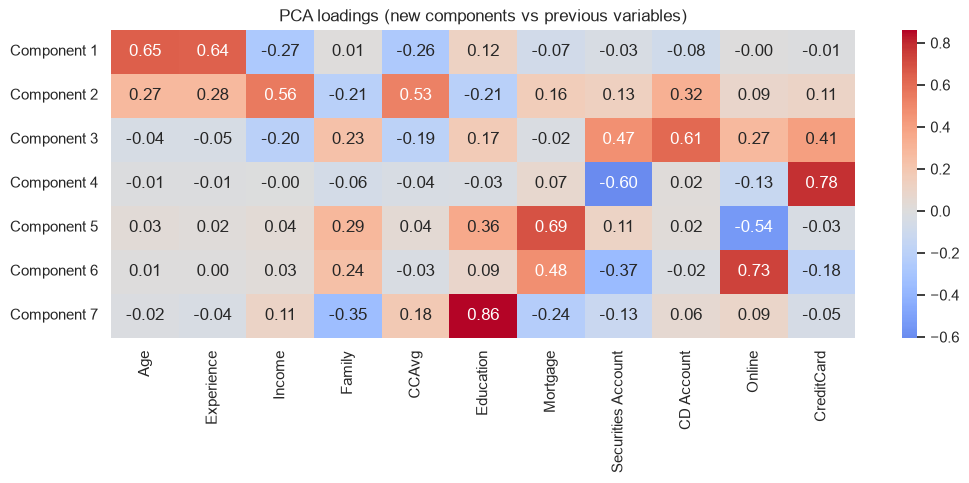

In [17]:
plt.figure(figsize=(12, 4))
sns.heatmap(df_pca_comp, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('PCA loadings (new components vs previous variables)')
plt.show()

In [18]:
scores_pca = pca.transform(data_scaled)

pca_df = pd.DataFrame(scores_pca, columns=[f'Variable_{i+1}' for i in range(n_comp)])
pca_df.head()

,Variable_1,Variable_2,Variable_3,Variable_4,Variable_5,Variable_6,Variable_7
0,-2.159556,-1.390897,1.064576,-2.179782,0.476330,-1.918307,-1.703243
1,0.077668,-0.502120,0.797316,-2.152529,0.291316,-2.115114,-1.538983
2,-0.177055,-1.265884,-0.920618,-0.046504,-0.614691,-1.346826,-0.610682
3,-1.432306,-0.055628,-1.299094,-0.121304,-0.082964,-1.226807,0.865491
4,-0.851711,-1.691718,0.667393,1.476671,0.506804,-0.996245,-0.503555


In [19]:
wcss_pca = []
silhouette_scores_pca = []

for i in range(1, 8):
    kmeans_pca = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans_pca.fit(pca_df)

    wcss_pca.append(kmeans_pca.inertia_)
    print(f"Cluster {i}: WCSS = {kmeans_pca.inertia_:.4f}")

    if i > 1:
        sil = silhouette_score(pca_df, kmeans_pca.predict(pca_df))
        silhouette_scores_pca.append(sil)
        print(f"Silhouette Score = {sil:.4f}")
    else:
        print(" (Silhouette Score not applicable for k=1)")

Cluster 1: WCSS = 46030.8070
 (Silhouette Score not applicable for k=1)
Cluster 2: WCSS = 38502.1029
Silhouette Score = 0.1663
Cluster 3: WCSS = 33283.1513
Silhouette Score = 0.1861
Cluster 4: WCSS = 29058.3580
Silhouette Score = 0.1906
Cluster 5: WCSS = 26954.1755
Silhouette Score = 0.1704
Cluster 6: WCSS = 24896.0569
Silhouette Score = 0.1783
Cluster 7: WCSS = 23342.6866
Silhouette Score = 0.1751


The optimal number of clusters (elbow point) is: 4


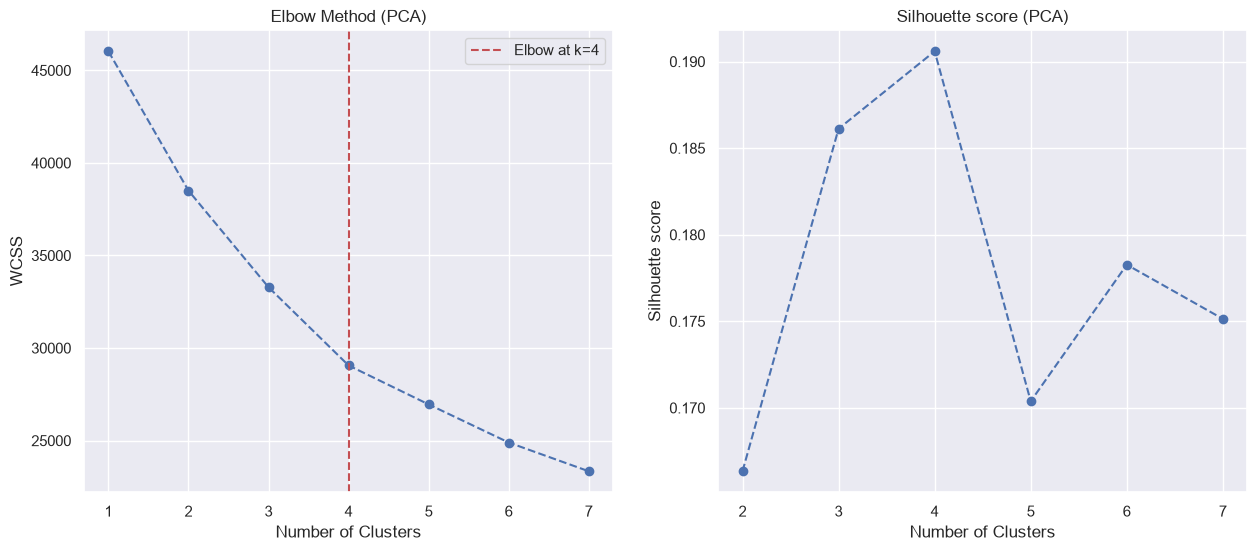

In [20]:
knee_locator = KneeLocator(range(1, 8), wcss_pca, curve="convex", direction="decreasing")
optimal_k_pca = knee_locator.elbow
print(f"The optimal number of clusters (elbow point) is: {optimal_k_pca}")

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
ax[0].plot(range(1, 8), wcss_pca, marker="o", linestyle="--")
ax[0].axvline(optimal_k_pca, linestyle="--", color="r", label=f"Elbow at k={optimal_k_pca}")
ax[0].set_xlabel("Number of Clusters"); ax[0].set_ylabel("WCSS"); ax[0].set_title("Elbow Method (PCA)"); ax[0].legend()

ax[1].plot(range(2, 8), silhouette_scores_pca, marker="o", linestyle="--")
ax[1].set_xlabel("Number of Clusters"); ax[1].set_ylabel("Silhouette score"); ax[1].set_title("Silhouette score (PCA)")
plt.show()

In [21]:
kmeans_pca = KMeans(n_clusters=optimal_k_pca, random_state=42, n_init=10)
kmeans_pca.fit(pca_df)

data['Segment_KM_PCA'] = kmeans_pca.predict(pca_df)
data = pd.concat([data, pca_df], axis=1)

data.head()

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard,Segment_KM,Segment_KM_PCA,Variable_1,Variable_2,Variable_3,Variable_4,Variable_5,Variable_6,Variable_7
0,25,1,49.0,4,1.6,1,0.0,1,0,0,0,1,3,-2.159556,-1.390897,1.064576,-2.179782,0.476330,-1.918307,-1.703243
1,45,19,34.0,3,1.5,1,0.0,1,0,0,0,1,3,0.077668,-0.502120,0.797316,-2.152529,0.291316,-2.115114,-1.538983
2,39,15,11.0,1,1.0,1,0.0,0,0,0,0,1,3,-0.177055,-1.265884,-0.920618,-0.046504,-0.614691,-1.346826,-0.610682
3,35,9,100.0,1,2.7,2,0.0,0,0,0,0,1,2,-1.432306,-0.055628,-1.299094,-0.121304,-0.082964,-1.226807,0.865491
4,35,8,45.0,4,1.0,2,0.0,0,0,0,1,1,3,-0.851711,-1.691718,0.667393,1.476671,0.506804,-0.996245,-0.503555


In [22]:
segment_table('Segment_KM_PCA')

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard,customer count,share of customers,loan acceptance rate
Segment_KM_PCA,,,,,,,,,,,,,,
0,45.730,20.586,104.132,2.457,2.661,1.934,72.709,0.490,0.993,0.931,0.796,304,0.061,0.461
1,55.555,30.238,54.263,2.430,1.262,2.010,42.551,0.079,0.000,0.600,0.282,1942,0.388,0.027
2,44.389,19.371,136.188,1.752,3.811,1.421,71.994,0.059,0.000,0.548,0.205,902,0.180,0.256
3,35.024,9.798,58.429,2.665,1.328,1.961,44.707,0.090,0.000,0.563,0.268,1852,0.370,0.030


**Target group (K-Means + PCA): Segment_KM_PCA = 2** - 902 customers (18%), income about 136, CCAvg about 3.8, 26% loan acceptance. It is the same group as Segment_KM = 0, so PCA does not change the picture. Segment 0 (304 customers, CD account holders, 46%) is again the small second choice.

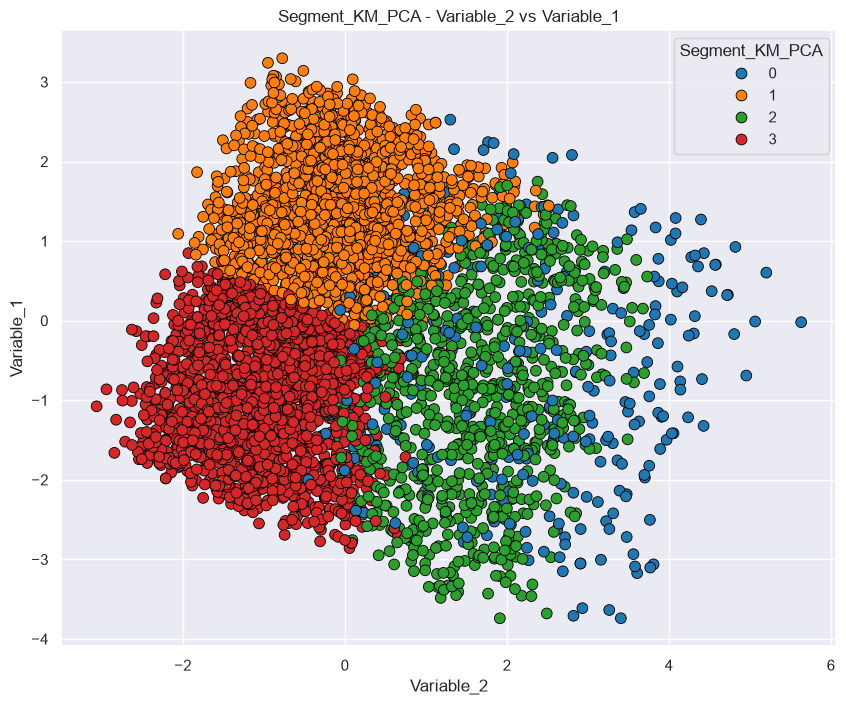

In [23]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x=data['Variable_2'], y=data['Variable_1'], hue=data['Segment_KM_PCA'], palette='tab10', s=60, edgecolor="black")
plt.title('Segment_KM_PCA - Variable_2 vs Variable_1')
plt.show()

## 3. AgglomerativeClustering model by default

- Build Dendogram to detect centroids for scaled data
- Build AgglomerativeClustering model by preferred centroid
- Create target cluster predicting on data and name column as segment_HC
- Analyse each cluster by groupby method ( Which one is your target group )
- Plot scatter between choosen columns by given segment_HC

Biggest gap is between 54.8 and 83.4
threshold: 69.1 -> number of clusters: 5


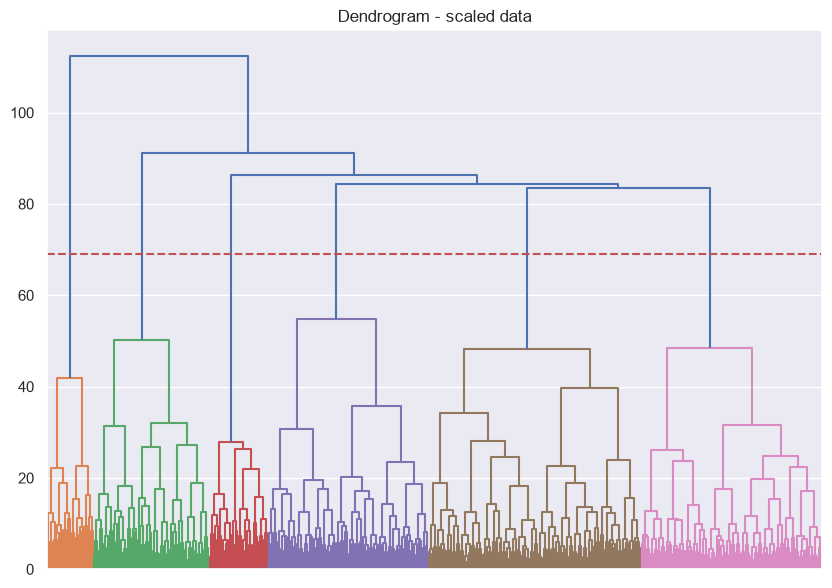

In [24]:
lines = shc.linkage(data_scaled, method='ward')

# biggest gap between the last merges -> place the threshold in the middle of it
h = lines[-10:, 2]
gaps = np.diff(h)
i = gaps.argmax()
print("Biggest gap is between", round(h[i], 1), "and", round(h[i+1], 1))

threshold_hc = (h[i] + h[i+1]) / 2
k_hc = len(h) - i - 1
print('threshold:', round(threshold_hc, 1), '-> number of clusters:', k_hc)

plt.figure(figsize=(10, 7))
plt.title("Dendrogram - scaled data")
shc.dendrogram(lines, no_labels=True)
plt.axhline(y=threshold_hc, color='r', linestyle='--')
plt.show()

In [25]:
cluster = AgglomerativeClustering(n_clusters=k_hc, linkage='ward')
data['segment_HC'] = cluster.fit_predict(data_scaled)

data['segment_HC'].value_counts().sort_index()

segment_HC
0    2535
1    1038
2     750
3     375
4     302
Name: count, dtype: int64

In [26]:
segment_table('segment_HC')

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard,customer count,share of customers,loan acceptance rate
segment_HC,,,,,,,,,,,,,,
0,44.925,19.663,58.670,2.488,1.392,2.000,40.271,0.000,0.0,0.617,0.000,2535,0.507,0.047
1,45.123,19.853,58.448,2.498,1.378,1.951,42.389,0.000,0.0,0.559,1.000,1038,0.208,0.030
2,47.036,22.025,136.195,1.865,3.655,1.373,90.263,0.000,0.0,0.492,0.196,750,0.150,0.241
3,45.040,19.768,66.832,2.507,1.748,1.864,44.229,1.000,0.0,0.504,0.120,375,0.075,0.024
4,45.702,20.573,104.242,2.460,2.652,1.927,73.190,0.487,1.0,0.937,0.795,302,0.060,0.464


**Target group (Agglomerative, 5 clusters): segment_HC = 2** - 750 customers (15%), income about 136, CCAvg about 3.7, biggest mortgage (about 90), 24% loan acceptance.
Segment 4 (302 customers, 6%, all with a CD account, 46%) is a small niche. Segments 0 and 1 are half of all customers but accept only 3-5% (segment 1 = all card holders, segment 0 = nobody has a card).

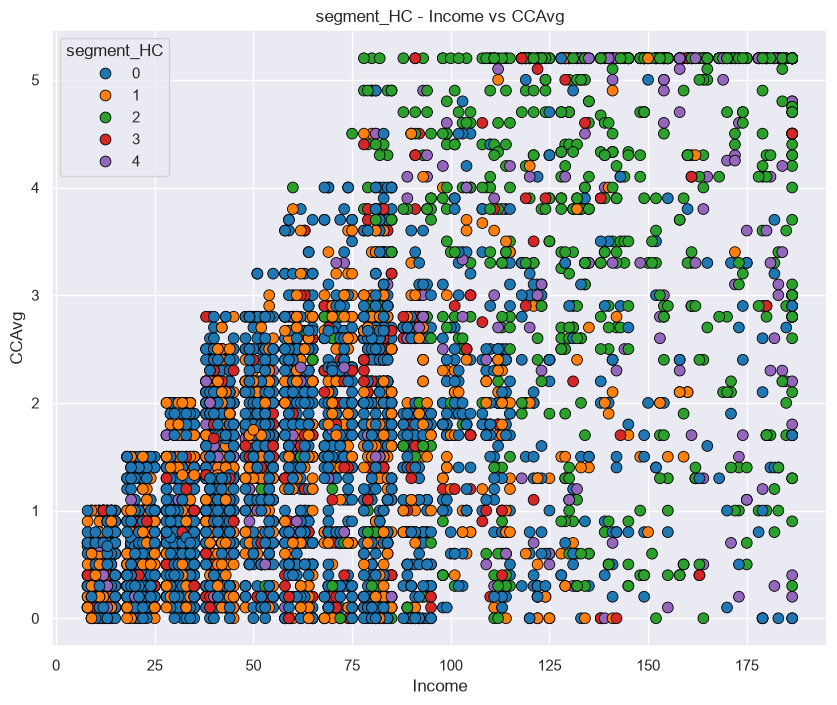

In [27]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x=data['Income'], y=data['CCAvg'], hue=data['segment_HC'], palette='tab10', s=60, edgecolor="black")
plt.title('segment_HC - Income vs CCAvg')
plt.show()

## 4. AgglomerativeClustering model by PCA

- Build Dendogram to detect centroids for pca_df
- Build AgglomerativeClustering model by preferred centroid
- Create target cluster predicting on data and name column as segment_HC_PCA 
- Analyse each cluster by groupby method ( Which one is your target group )
- Plot scatter between data['Variable_2'] and data['Variable_1'] columns by given segment_HC_PCA

Biggest gap is between 53.4 and 72.9
threshold: 63.1 -> number of clusters: 4


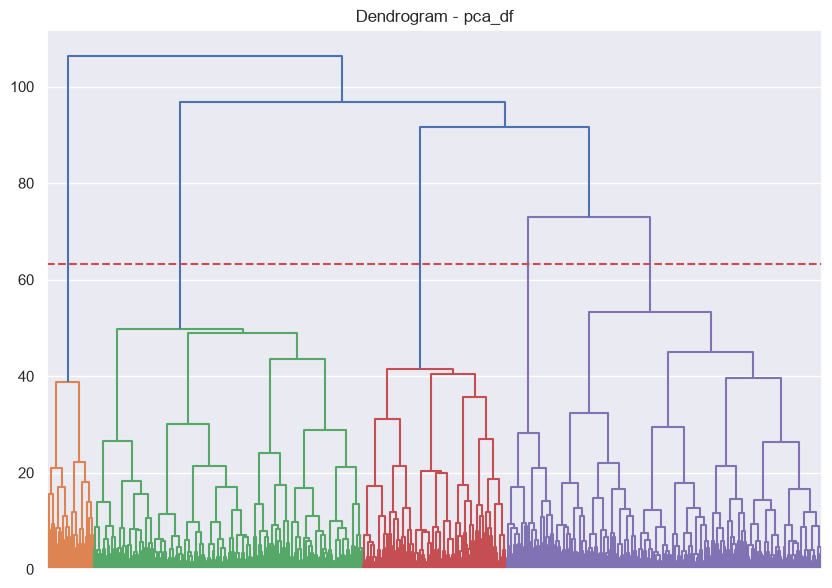

In [28]:
lines_pca = shc.linkage(pca_df, method='ward')

h = lines_pca[-10:, 2]
gaps = np.diff(h)
i = gaps.argmax()
print("Biggest gap is between", round(h[i], 1), "and", round(h[i+1], 1))

threshold_hc_pca = (h[i] + h[i+1]) / 2
k_hc_pca = len(h) - i - 1
print('threshold:', round(threshold_hc_pca, 1), '-> number of clusters:', k_hc_pca)

plt.figure(figsize=(10, 7))
plt.title("Dendrogram - pca_df")
shc.dendrogram(lines_pca, no_labels=True)
plt.axhline(y=threshold_hc_pca, color='r', linestyle='--')
plt.show()

In [29]:
cluster_pca = AgglomerativeClustering(n_clusters=k_hc_pca, linkage='ward')
data['segment_HC_PCA'] = cluster_pca.fit_predict(pca_df)

data['segment_HC_PCA'].value_counts().sort_index()

segment_HC_PCA
0    2032
1     929
2    1737
3     302
Name: count, dtype: int64

In [30]:
segment_table('segment_HC_PCA')

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Securities Account,CD Account,Online,CreditCard,customer count,share of customers,loan acceptance rate
segment_HC_PCA,,,,,,,,,,,,,,
0,37.613,12.384,56.757,2.673,1.319,1.887,46.261,0.153,0.0,0.523,0.299,2032,0.406,0.031
1,44.139,19.100,128.900,1.800,3.576,1.426,45.841,0.070,0.0,0.651,0.222,929,0.186,0.221
2,54.954,29.635,58.450,2.381,1.355,2.109,53.991,0.000,0.0,0.595,0.240,1737,0.347,0.041
3,45.702,20.573,104.242,2.460,2.652,1.927,73.190,0.487,1.0,0.937,0.795,302,0.060,0.464


**Target group (Agglomerative + PCA, 4 clusters): segment_HC_PCA = 1** - 929 customers (18.6%), income about 129, CCAvg about 3.6, 22% loan acceptance. Same type of customer as in the other three methods. Segment 3 (302 customers, CD account, 46%) again is the small high-conversion niche.

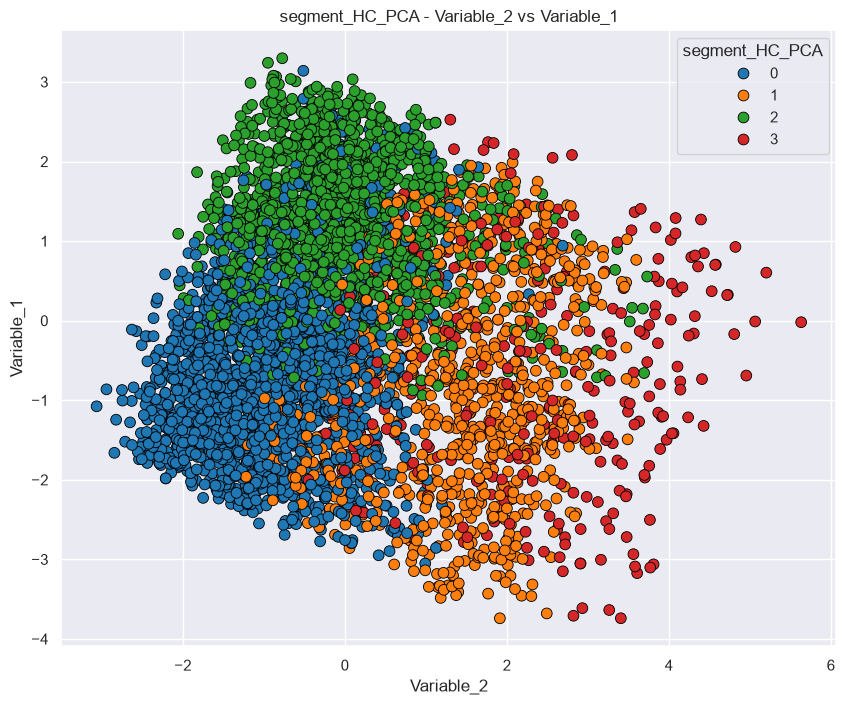

In [31]:
plt.figure(figsize=(10, 8))
sns.scatterplot(x=data['Variable_2'], y=data['Variable_1'], hue=data['segment_HC_PCA'], palette='tab10', s=60, edgecolor="black")
plt.title('segment_HC_PCA - Variable_2 vs Variable_1')
plt.show()

In [32]:
pca_cols = [f'Variable_{i+1}' for i in range(n_comp)]

pd.DataFrame({'Silhouette': {
    'K-means':           silhouette_score(data_scaled, data['Segment_KM']),
    'K-means + PCA':     silhouette_score(data[pca_cols], data['Segment_KM_PCA']),
    'Agglomerative':     silhouette_score(data_scaled, data['segment_HC']),
    'Agglomerative+PCA': silhouette_score(data[pca_cols], data['segment_HC_PCA']),
}}).sort_values('Silhouette', ascending=False).round(4)

,Silhouette
K-means + PCA,0.1906
K-means,0.1609
Agglomerative,0.1488
Agglomerative+PCA,0.1417


## Final choice

All four methods find the **same target group**: high income (about 130-140), high credit card spending (CCAvg about 3.6-3.9), small families (about 1.8 members), mostly with a university/graduate degree. It is 15-19% of customers and 22-27% of them accepted a personal loan, against 2-5% in the big low-income groups.

The CD-account customers (about 6%) are a very small group with the highest acceptance (46%) - a good second target for a cheap, personal offer.

Silhouette scores are low (see the last table), so the groups overlap; the segments are a guide for marketing, not sharp borders. K-Means + PCA has the best silhouette score.